In [70]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.special import jv

In [111]:
pi = np.pi
lamb = 1
a = 50*lamb
k = (2*pi)/lamb
eta = 120*pi
num = 181

theta = np.linspace(-pi/18, pi/2, 1442) #721
phi   = np.linspace(0, pi/2, 181)

# --- grades finas o bastante para ka ~ 314 ---
Nrho = 1001                                   # ímpar, para Simpson                          
Nphp = 1024  # pontos em phi' (periódico)
rho_l = np.linspace(0, a, Nrho)
phi_l = np.linspace(0, 2*np.pi, Nphp, endpoint=False)

# --- integral numérica, só para phi = 0 (I não depende de phi) ---
I_th = np.zeros(len(theta), dtype=complex)
RHO  = rho_l[:, None]
COS  = np.cos(phi_l)[None, :]                 # cos(0 - phi')

for i, th in enumerate(theta):
    integrando = RHO * np.exp(1j*k*RHO*np.sin(th)*COS)     # (rho', phi')
    Iphi = integrando.mean(axis=1) * 2*np.pi                  # trapézio periódico em phi'
    I_th[i] = simpson(Iphi, x=rho_l)                          # Simpson em rho'

# --- campos: broadcasting, I é independente de phi ---
TH, PH = np.meshgrid(theta, phi, indexing='ij')
I = I_th[:, None]

E_theta =  np.cos(TH)*np.cos(PH)*I * ((-1j*k*eta)/(4*pi))
E_phi   = -np.sin(PH)*I* ((-1j*k*eta)/(4*pi))

In [146]:
TH, PH = np.meshgrid(theta, phi, indexing='ij')
Eco = E_theta*np.cos(PH)-E_phi*np.sin(PH)
Gco =  np.abs(Eco)**2 * 16*(1/(eta*a))**2    
Gco = 10*np.log10(Gco + 1e-12)

Ecx = E_theta*np.sin(PH) + E_phi*np.sin(PH)
Gcx =  np.abs(Ecx)**2 * 16*(1/(eta*a))**2    
Gcx = 10*np.log10(Gcx + 1e-12)

Solução analítica

In [147]:
num2 = 2000  ### Número de pontos
theta2 = np.linspace(-pi/18,pi,num2)
phi2 = np.linspace(0,pi/2,num2)

TH, PH = np.meshgrid(theta2, phi2, indexing='ij')

u = k*np.sin(theta2)          # vetor em theta
x = u*a

# --- Caso A: peso rho' ---
I_theta = np.where(np.abs(x) > 1e-8,
                   2*pi*a*jv(1, x)/np.where(np.abs(x) > 1e-8, u, 1),
                   pi*a**2)                  # limite em u -> 0

I = np.tile(I_theta[:, None], (1, num2))         # I[theta, phi], independe de phi

Ea_theta =  np.cos(TH)*np.cos(PH)*I * ((-1j*k*eta)/(4*pi))
Ea_phi   = -np.sin(PH)*I * ((-1j*k*eta)/(4*pi))

Eaco = Ea_theta*np.cos(PH)-Ea_phi*np.sin(PH)
Gaco = 16*(1/(eta*a))**2 * np.abs(Eaco)**2
Gaco = 10*np.log10(Gaco + 1e-12)

Eacx = Ea_theta*np.sin(PH) + Ea_phi*np.sin(PH)
Gacx =  np.abs(Eacx)**2 * 16*(1/(eta*a))**2    
Gacx = 10*np.log10(Gacx + 1e-12)

49.94142541263379


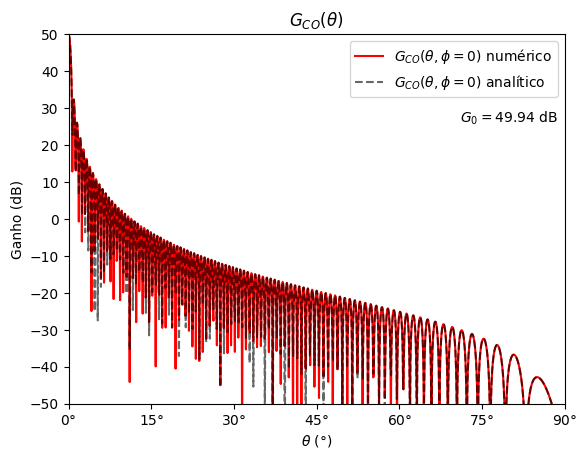

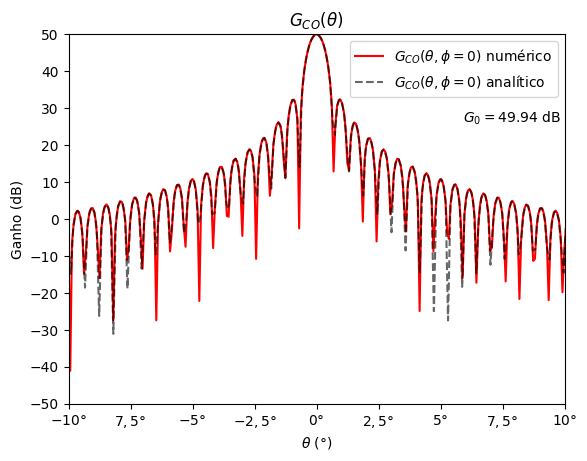

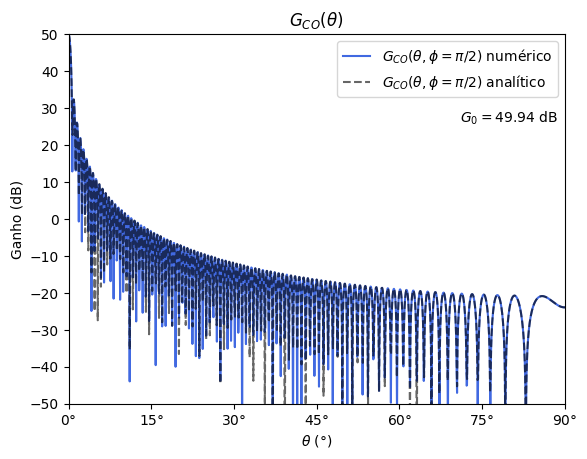

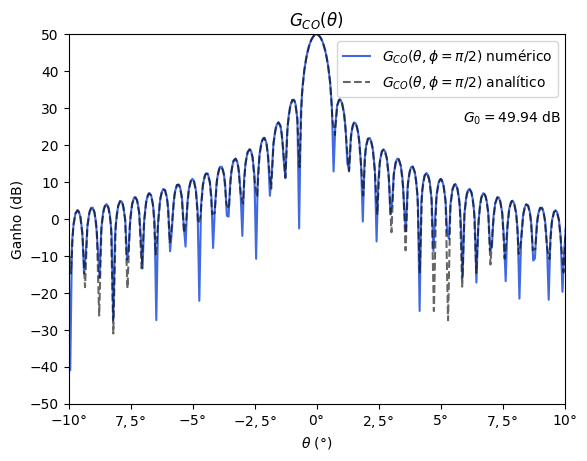

In [148]:
print(np.max(np.real(Gco[:,-1])))

plt.figure()
plt.title(r'$G_{CO}(\theta)$')
plt.plot(theta,np.real(Gco[:,0]),label=r'$G_{CO}(\theta,\phi=0)$ numérico',color='red')
plt.plot(theta2,np.real(Gaco[:,0]),label=r'$G_{CO}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                     [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
plt.xlim(0,pi/2)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylim(-50,50)
plt.ylabel('Ganho (dB)')
plt.text(x=0.79*(pi/2),y=26,s=r'$G_0=49.94$ dB')
plt.yticks(np.arange(-50,51,10))
plt.show()

plt.figure()
plt.title(r'$G_{CO}(\theta)$')
plt.plot(theta,np.real(Gco[:,0]),label=r'$G_{CO}(\theta,\phi=0)$ numérico',color='red')
plt.plot(theta2,np.real(Gaco[:,0]),label=r'$G_{CO}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                    [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
plt.xlim(-pi/18,pi/18)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylim(-50,50)
plt.ylabel('Ganho (dB)')
plt.text(x=0.59*(pi/18),y=26,s=r'$G_0=49.94$ dB')
plt.yticks(np.arange(-50,51,10))
plt.show()

plt.figure()
plt.title(r'$G_{CO}(\theta)$')
plt.plot(theta,np.real(Gco[:,-1]),label=r'$G_{CO}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
plt.plot(theta2,np.real(Gaco[:,-1]),label=r'$G_{CO}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                    [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
plt.xlim(0,pi/2)
plt.ylim(-50,50)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylabel('Ganho (dB)')
plt.text(x=0.79*(pi/2),y=26,s=r'$G_0=49.94$ dB')
plt.yticks(np.arange(-50,51,10))
plt.show()

plt.figure()
plt.title(r'$G_{CO}(\theta)$')
plt.plot(theta,np.real(Gco[:,-1]),label=r'$G_{CO}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
plt.plot(theta2,np.real(Gaco[:,-1]),label=r'$G_{CO}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                    [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
plt.xlim(-pi/18,pi/18)
plt.ylim(-50,50)
plt.yticks(np.arange(-50,51,10))
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylabel('Ganho (dB)')
plt.text(x=0.59*(pi/18),y=26,s=r'$G_0=49.94$ dB')
plt.show()

-120.0
49.94142541263379


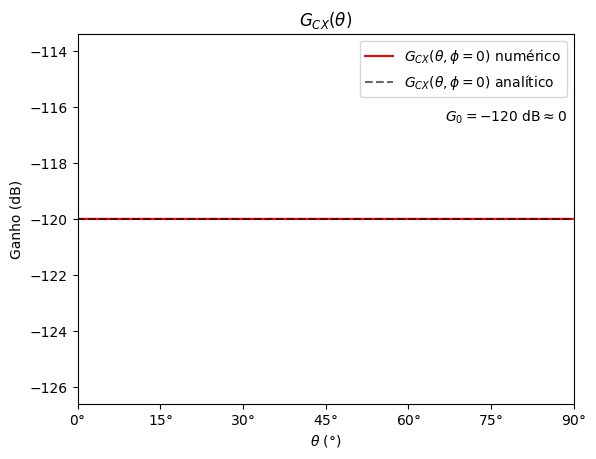

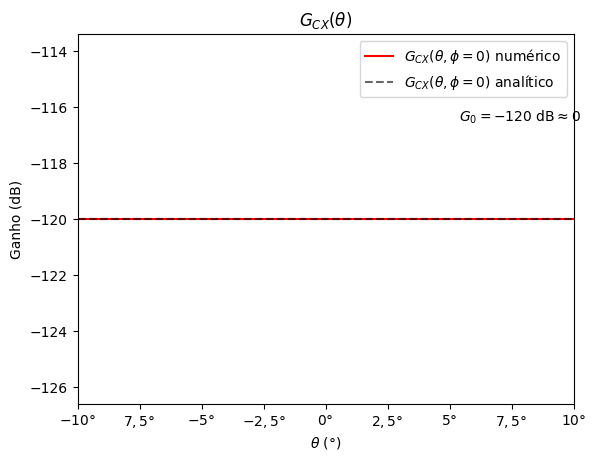

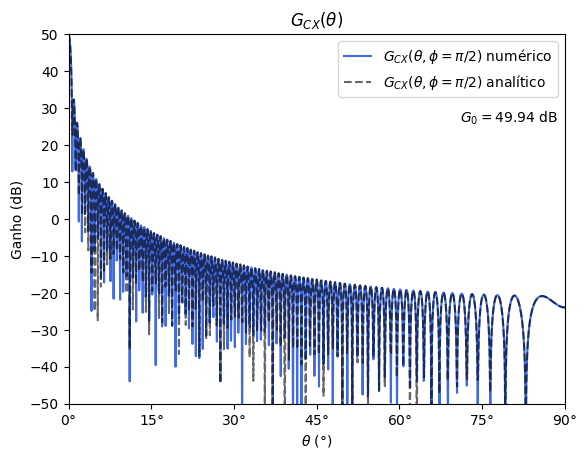

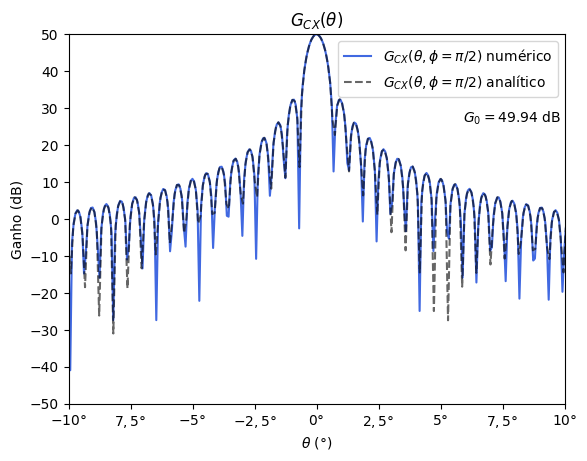

In [163]:
print(np.max(np.real(Gcx[:,0])))
print(np.max(np.real(Gcx[:,-1])))

plt.figure()
plt.title(r'$G_{CX}(\theta)$')
plt.plot(theta,np.real(Gcx[:,0]),label=r'$G_{CX}(\theta,\phi=0)$ numérico',color='red')
plt.plot(theta2,np.real(Gacx[:,0]),label=r'$G_{CX}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                     [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
plt.xlim(0,pi/2)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
#plt.ylim(-50,50)
plt.ylabel('Ganho (dB)')
plt.text(x=0.74*(pi/2),y=-116.5,s=r'$G_0=-120$ dB$\approx 0 $')
#plt.yticks(np.arange(-50,51,10))
plt.show()

plt.figure()
plt.title(r'$G_{CX}(\theta)$')
plt.plot(theta,np.real(Gcx[:,0]),label=r'$G_{CX}(\theta,\phi=0)$ numérico',color='red')
plt.plot(theta2,np.real(Gacx[:,0]),label=r'$G_{CX}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                    [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
plt.xlim(-pi/18,pi/18)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
#plt.ylim(-50,50)
plt.ylabel('Ganho (dB)')
plt.text(x=0.54*(pi/18),y=-116.5,s=r'$G_0=-120$ dB$\approx 0 $')
# plt.yticks(np.arange(-50,51,10))
plt.show()

plt.figure()
plt.title(r'$G_{CX}(\theta)$')
plt.plot(theta,np.real(Gcx[:,-1]),label=r'$G_{CX}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
plt.plot(theta2,np.real(Gacx[:,-1]),label=r'$G_{CX}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                    [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
plt.xlim(0,pi/2)
plt.ylim(-50,50)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylabel('Ganho (dB)')
plt.text(x=0.79*(pi/2),y=26,s=r'$G_0=49.94$ dB')
plt.yticks(np.arange(-50,51,10))
plt.show()

plt.figure()
plt.title(r'$G_{CX}(\theta)$')
plt.plot(theta,np.real(Gcx[:,-1]),label=r'$G_{CX}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
plt.plot(theta2,np.real(Gacx[:,-1]),label=r'$G_{CX}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                    [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
plt.xlim(-pi/18,pi/18)
plt.ylim(-50,50)
plt.yticks(np.arange(-50,51,10))
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylabel('Ganho (dB)')
plt.text(x=0.59*(pi/18),y=26,s=r'$G_0=49.94$ dB')
plt.show()

A solução numérica foi truncada em $-120$ dB, que fisicamente corresponde a $G_0 \rightarrow - \infty$ dB, isto é $G_0 \rightarrow 0$